# IMF Maldives 2024 Article IV — Complete LLM Research Assignment
**Source:** IMF Country Report No. 24/106 (May 2024), 2024 Article IV Consultation (102 PDF pages).  
**Tasks:** PDF processing, grounded summarisation and dual-LLM audit; thematic and numerical extraction; local FAISS RAG; high-resolution analytics; multi-query retrieval benchmarking.

**Evidence convention:** 2021–2022 actual; 2023 IMF estimate; 2024–2029 IMF projections. Financial soundness data end in **2023 Q3**. Do not mistake IMF projections for realised outcomes. The 2024 GDP and inflation figures use *Table 1* (PDF page 34); financial soundness figures use *Table 6* (PDF page 39). Always check table definitions before interpreting metrics.

**Code documentation:** Python functions use PEP 257-style docstrings, and executable cells have been reformatted with standard-library AST formatting for readable, PEP 8-oriented spacing. The original workflow and analytical parameters are retained. External API calls and Colab execution have not been rerun.

## 0. Installation and setup

In [ ]:
%pip -q install pymupdf tiktoken sentence-transformers faiss-cpu google-genai seaborn pydantic

In [ ]:
"""Configure dependencies, input PDF discovery, and output paths."""

# To persist outputs on Drive, change OUT to Path('/content/drive/MyDrive/IMF_2024_Outputs') and mkdir.

from pathlib import Path
import os, re, json, time, hashlib, collections, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
OUT = Path('/content/drive/MyDrive/IMF_2024_Outputs')
OUT.mkdir(parents=True, exist_ok=True)
PDF_CANDIDATES = [Path('/mnt/data/null-002.2024.issue-106-en.pdf'), Path('/content/drive/MyDrive/null-002.2024.issue-106-en.pdf'), Path('null-002.2024.issue-106-en.pdf')]
PDF_PATH = next((p for p in PDF_CANDIDATES if p.exists()), None)
if PDF_PATH is None:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PDF_PATH = next((p for p in PDF_CANDIDATES if p.exists()), None)
    except ImportError:
        pass
if PDF_PATH is None:
    try:
        from google.colab import files
        up = files.upload()
        PDF_PATH = Path(next(iter(up)))
    except ImportError:
        raise FileNotFoundError('Set PDF_PATH to the 2024 IMF PDF')
assert PDF_PATH.is_file()
print('Loaded:', PDF_PATH, 'SHA256:', hashlib.sha256(PDF_PATH.read_bytes()).hexdigest())


Mounted at /content/drive
Loaded: /content/drive/MyDrive/null-002.2024.issue-106-en.pdf SHA256: eda20d31a80438ee09cfc34823f1c6a137a6c6baee6b55edbd675eaabb7c7f78


## Task 1 — PDF extraction, cleaning, token-aware chunks, summaries and audit

In [ ]:
"""Extract PDF pages, clean text, and create overlapping token-aware chunks."""

import fitz, tiktoken
pdf = fitz.open(PDF_PATH)

def clean_text(s):
    """Clean text extracted from one IMF PDF page.

    Remove common PDF ligatures, repair line-break hyphenation, discard
    selected repeating headers and page numbers, and normalise whitespace.

    Args:
        s (str): Raw page text extracted using PyMuPDF.

    Returns:
        str: Cleaned page text for tokenisation and downstream analysis.

    Notes:
        Heuristic cleaning can remove meaningful standalone numeric lines.
    """
    s = s.replace('\xad', '').replace('ﬁ', 'fi').replace('ﬂ', 'fl')
    s = re.sub('(?<=\\w)-\\n(?=\\w)', '', s)
    lines = [x.strip() for x in s.splitlines()]
    lines = [x for x in lines if x and (not re.fullmatch('(?:MALDIVES|INTERNATIONAL MONETARY FUND|©International Monetary Fund.*|\\d{1,3})', x, re.I))]
    return re.sub('\\s+', ' ', ' '.join(lines)).strip()
pages = [{'page': i + 1, 'text': clean_text(p.get_text(sort=True))} for i, p in enumerate(pdf)]
assert len(pages) > 50
(OUT / 'pages.json').write_text(json.dumps(pages, ensure_ascii=False, indent=2))
enc = tiktoken.get_encoding('cl100k_base')
CHUNK_SIZE = 400
OVERLAP = 50
chunks = []
for p in pages:
    toks = enc.encode(p['text'])
    for start in range(0, len(toks), CHUNK_SIZE - OVERLAP):
        part = toks[start:start + CHUNK_SIZE]
        if not part:
            break
        chunks.append({'id': len(chunks), 'page': p['page'], 'text': enc.decode(part), 'token_count': len(part)})
        if start + CHUNK_SIZE >= len(toks):
            break
(OUT / 'chunks.json').write_text(json.dumps(chunks, ensure_ascii=False, indent=2))
print(len(pages), 'pages;', len(chunks), 'overlapping chunks; preview:', chunks[0]['text'][:250])


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


102 pages; 229 overlapping chunks; preview: IMF Country Report No. 24/106 2024 ARTICLE IV CONSULTATION—PRESS RELEASE; May 2024 STAFF REPORT; AND STATEMENT BY THE EXECUTIVE DIRECTOR FOR MALDIVES Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions with member


### Section boundaries
Section titles are taken from the **staff report contents** (PDF page 7), with approximate PDF boundaries. Annexes and the Debt Sustainability Analysis are separately included. Verify boundaries against the PDF when editing your submission.

In [ ]:
"""Define report sections and their PDF page ranges."""

SECTION_RANGES = {'Press release and executive board assessment': (3, 5), 'Staff report: context': (9, 9), 'Recent developments': (10, 11), 'Outlook and risks': (11, 13), 'Key policy issues — fiscal policy': (14, 17), 'Monetary and exchange rate policies': (18, 19), 'Financial sector policies': (20, 21), 'Climate change and structural reforms': (22, 24), 'Staff appraisal': (24, 26), 'Economic and financial figures and tables': (27, 41), 'Annexes and technical analysis': (42, 76), 'Debt sustainability and concluding material': (77, len(pages))}
sections = {k: ' '.join((p['text'] for p in pages if lo <= p['page'] <= hi)) for k, (lo, hi) in SECTION_RANGES.items()}
print({k: len(v.split()) for k, v in sections.items()})


{'Press release and executive board assessment': 1316, 'Staff report: context': 481, 'Recent developments': 917, 'Outlook and risks': 1482, 'Key policy issues — fiscal policy': 1919, 'Monetary and exchange rate policies': 1014, 'Financial sector policies': 759, 'Climate change and structural reforms': 1458, 'Staff appraisal': 1167, 'Economic and financial figures and tables': 6139, 'Annexes and technical analysis': 13564, 'Debt sustainability and concluding material': 11809}


### Gemini generation and independent evaluation
Set `GEMINI_API_KEY` in Colab Secrets or environment. The generator receives page-numbered evidence and must avoid unsupported claims. The judge independently checks consistency, completeness and factual alignment. **If no API key is provided, summaries are not fabricated.**

In [ ]:
"""Configure Gemini generation, evaluation, and source-evidence prompts."""

from google import genai
API_KEY = os.environ.get('GEMINI_API_KEY', '')
if not API_KEY:
    try:
        from google.colab import userdata
        API_KEY = userdata.get('GEMINI_API_KEY') or ''
    except Exception:
        pass
client = genai.Client(api_key=API_KEY) if API_KEY else None
GEN_MODEL = os.getenv('GEN_MODEL', 'gemini-3.8-flash')
JUDGE_MODEL = os.getenv('JUDGE_MODEL', 'gemini-3.5-flash-lite')

def llm(prompt, model=GEN_MODEL, system=None):
    """Generate text using the configured Gemini model.

    Args:
        prompt (str): Instructions and source evidence supplied to the model.
        model (str): Model identifier; defaults to the generation model.
        system (str | None): Optional system-level instructions.

    Returns:
        str: Generated response text, or an empty string if unavailable.

    Raises:
        RuntimeError: If the Gemini API client has not been configured.

    Notes:
        Temperature zero does not guarantee factual accuracy.
    """
    if client is None:
        raise RuntimeError('Set GEMINI_API_KEY before LLM cells')
    from google.genai import types
    response = client.models.generate_content(model=model, contents=prompt, config=types.GenerateContentConfig(temperature=0, system_instruction=system))
    return response.text or ''

def source_excerpt(lo, hi, limit=26000):
    """Collect page-labelled source evidence from extracted PDF pages.

    Args:
        lo (int): First PDF page to include, inclusive.
        hi (int): Last PDF page to include, inclusive.
        limit (int): Maximum number of characters returned.

    Returns:
        str: Joined page-labelled text, truncated to the character limit.

    Notes:
        Truncation may omit relevant evidence.
    """
    s = '\n'.join((f"[PDF page {p['page']}] {p['text']}" for p in pages if lo <= p['page'] <= hi))
    return s[:limit]
SYSTEM_SUM = 'You are a careful IMF research analyst. Use only provided source passages. Include PDF page citations. Never infer unreported figures, dates or trends. Distinguish historical, estimated and projected values.'
SYSTEM_JUDGE = 'You are an independent factual auditor. Only award credit for statements supported by the supplied IMF source. Return valid JSON with scores 0-5 and concrete evidence.'


In [ ]:
"""Run resumable map-reduce summarisation with retry and checkpoint logic."""

# Resumable map-reduce summarisation with exponential backoff for 429/5xx errors.

import random
CHECKPOINT = OUT / 'batch_summaries.json'

def llm_retry(prompt, system, retries=5):
    """Call the generation model with bounded retries for transient errors.

    Args:
        prompt (str): Generation prompt.
        system (str): System-level instructions.
        retries (int): Maximum number of attempts.

    Returns:
        str: Successful model response.

    Raises:
        Exception: Propagates non-transient errors or the final failed attempt.
    """
    for attempt in range(retries):
        try:
            return llm(prompt, system=system)
        except Exception as exc:
            message = str(exc).lower()
            if not any((term in message for term in ('503', 'unavailable', '429', 'resource_exhausted', '500', '502', '504'))):
                raise
            if attempt == retries - 1:
                raise
            delay = min(60, 3 * 2 ** attempt) + random.uniform(0, 1)
            print(f'Temporary Gemini error; retrying in {delay:.1f}s')
            time.sleep(delay)
if client:
    batch_summaries = json.loads(CHECKPOINT.read_text()) if CHECKPOINT.exists() else []
    completed = {entry['pages'] for entry in batch_summaries}
    total_batches = (len(pages) + 4) // 5
    for start in range(1, len(pages) + 1, 5):
        end = min(start + 4, len(pages))
        key = f'{start}-{end}'
        if key in completed:
            print('Already saved:', key)
            continue
        evidence = source_excerpt(start, end, limit=18000)
        prompt = 'Summarise substantive IMF findings and numerical claims in at most 130 words. Cite source PDF pages. Preserve caveats and distinguish actual, estimates and projections. Do not infer missing values.\n' + evidence
        try:
            result = llm_retry(prompt, system=SYSTEM_SUM)
        except Exception as exc:
            print(f'Stopped at pages {key}: {exc}. Rerun to resume.')
            break
        batch_summaries.append({'pages': key, 'summary': result})
        completed.add(key)
        CHECKPOINT.write_text(json.dumps(batch_summaries, indent=2, ensure_ascii=False))
        print('Saved:', key)
        time.sleep(2)
    if len(completed) == total_batches:
        ordered = sorted(batch_summaries, key=lambda x: int(x['pages'].split('-')[0]))
        executive_summary = llm_retry('Write 6–8 concise bullet points covering the complete IMF report: financial stability, key risks, projections and recommendations. Cite PDF pages from the evidence; do not invent facts.\n' + json.dumps(ordered, ensure_ascii=False), system=SYSTEM_SUM)
        (OUT / 'executive_summary.md').write_text(executive_summary, encoding='utf-8')
        print(executive_summary)
    else:
        print(f'Completed {len(completed)}/{total_batches} batches; executive summary postponed.')
else:
    print('LLM not run: add GEMINI_API_KEY; deterministic analysis remains available.')


Saved: 1-5
Saved: 6-10
Saved: 11-15
Saved: 16-20
Saved: 21-25
Saved: 26-30
Saved: 31-35
Saved: 36-40
Saved: 41-45
Saved: 46-50
Temporary Gemini error; retrying in 3.9s
Saved: 51-55
Saved: 56-60
Saved: 61-65
Saved: 66-70
Saved: 71-75
Saved: 76-80
Saved: 81-85
Saved: 86-90
Saved: 91-95
Saved: 96-100
Saved: 101-102
Here is a concise summary of the IMF report covering financial stability, key risks, projections, and recommendations:

* **Economic Activity & Growth Dynamics:** Historical actual real GDP expanded by 13.9% in 2022, driven by tourist arrivals that reached a historic high of 1.88 million in 2023 [PDF page 9–10, 98]. Real GDP growth is estimated to have moderated to 4.4% in 2023 and is projected to rise to 5.2% in 2024 and 6.5% in 2025 [PDF page 3, 11, 34, 98].
* **Fiscal Deficit & Debt Vulnerabilities:** The overall fiscal deficit is estimated at 13.4% of GDP for 2023 and projected at 12.2% in 2024 [PDF page 3, 12, 34]. Estimated 2023 public and publicly guaranteed (PPG) debt r

In [ ]:
"""Generate section summaries and evaluate them against source excerpts."""

# Use prior page batch summaries for long sections to avoid silent truncation

section_summaries = {}
section_audits = {}
if client:
    for title, (lo, hi) in SECTION_RANGES.items():
        if hi - lo > 6:
            evidence = '\n'.join((f"{x['pages']}: {x['summary']}" for x in batch_summaries if int(x['pages'].split('-')[0]) <= hi and int(x['pages'].split('-')[-1]) >= lo))
        else:
            evidence = source_excerpt(lo, hi, limit=23000)
        summary = llm(f'Summarise section "{title}" in FEWER THAN 100 words. Cite PDF page(s). Source:\n{evidence}', system=SYSTEM_SUM)
        section_summaries[title] = summary
        audit = llm('Return JSON with keys consistency, completeness, factual_alignment (integer 0-5), unsupported_claims (array), suggestions (array). Audit summary against evidence.\nEVIDENCE:\n' + evidence[:16000] + '\nSUMMARY:\n' + summary, model=JUDGE_MODEL, system=SYSTEM_JUDGE)
        section_audits[title] = audit
    (OUT / 'section_summaries.json').write_text(json.dumps(section_summaries, indent=2))
    (OUT / 'section_audits.json').write_text(json.dumps(section_audits, indent=2))
    display(pd.DataFrame({'section': list(section_summaries), 'summary': list(section_summaries.values())}))
else:
    print('Skipped LLM summaries and audits: API key required.')


,section,summary
0,Press release and executive board assessment,Following a strong post-pandemic recovery—with...
1,Staff report: context,"**Summary of ""Staff report: context"":**\n\nThe..."
2,Recent developments,**Recent Developments Summary:**\n\nFollowing ...
3,Outlook and risks,"Growth is projected at 5.2 percent in 2024, dr..."
4,Key policy issues — fiscal policy,Although past GST rate increases generated rev...
5,Monetary and exchange rate policies,The U.S. dollar peg serves as the nominal anch...
6,Financial sector policies,Despite a sound banking sector with non-perfor...
7,Climate change and structural reforms,Climate change poses an existential threat to ...
8,Staff appraisal,Following a strong post-pandemic recovery—with...
9,Economic and financial figures and tables,Historical real GDP grew 37.7% in 2021 and 13....


## Task 2 — Seven financial themes (no overlap double-counting)

In [ ]:
"""Count seven financial-stability themes without overlap double-counting."""

THEMES = {'Inflation & Prices': ['\\binflation\\b', '\\bconsumer price(?: index)?\\b', '\\bprice pressures?\\b', '\\bCPI\\b'], 'Interest Rates & Credit': ['\\binterest rates?\\b', '\\bcredit growth\\b', '\\bdomestic credit\\b', '\\blending\\b', '\\bborrowing costs?\\b'], 'Housing & Real Estate': ['\\breal estate\\b', '\\bhousing\\b', '\\bmortgage[s]?\\b', '\\bproperty market\\b', '\\bconstruction sector\\b'], 'Banking Capital & Liquidity': ['\\btier[ -]?1\\b', '\\bcapital adequacy\\b', '\\bcapital buffers?\\b', '\\bliquidity\\b', '\\breserve requirements?\\b', '\\bcapital ratio\\b'], 'Sovereign Debt': ['\\bsovereign debt\\b', '\\bpublic debt\\b', '\\bdebt sustainability\\b', '\\bgovernment securities\\b', '\\bdebt[- ]to[- ]GDP\\b', '\\bPPG debt\\b'], 'Labor Market Dynamics': ['\\bunemployment\\b', '\\blabou?r market\\b', '\\bemployment\\b', '\\bwage(?:s| growth)?\\b', '\\bworkforce\\b'], 'Systemic Financial Risk': ['\\bsystemic risks?\\b', '\\bfinancial stability\\b', '\\bstress test(?:ing|s)?\\b', '\\bsovereign.bank nexus\\b', '\\bfinancial vulnerabilities\\b', '\\bmacroprudential\\b']}
rows = []
for p in pages:
    for theme, patterns in THEMES.items():
        spans = set()
        for pat in patterns:
            spans.update(((m.start(), m.end()) for m in re.finditer(pat, p['text'], re.I)))
        rows.append({'page': p['page'], 'theme': theme, 'mentions': len(spans)})
theme_page = pd.DataFrame(rows)
theme_totals = theme_page.groupby('theme', as_index=False)['mentions'].sum()
total_words = sum((len(p['text'].split()) for p in pages))
theme_totals['per_1000_words'] = 1000 * theme_totals['mentions'] / total_words
for name, df in [('theme_counts_by_page', theme_page), ('theme_counts', theme_totals)]:
    df.to_json(OUT / f'{name}.json', orient='records', indent=2)
display(theme_totals.sort_values('mentions', ascending=False))


,theme,mentions,per_1000_words
5,Sovereign Debt,141,3.359222
6,Systemic Financial Risk,103,2.453900
0,Banking Capital & Liquidity,87,2.072712
3,Interest Rates & Credit,62,1.477105
2,Inflation & Prices,44,1.048268
1,Housing & Real Estate,11,0.262067
4,Labor Market Dynamics,8,0.190594


### Verified source-table numerical series
Rather than extracting year-value pairs from arbitrary narrative sentences (which produced empty or misleading graphs previously), these series are transcribed from **Table 1, PDF page 34**, and **Table 6, PDF page 39**, and checked against the text. The table's own 2023 estimate / 2024+ projections labels are retained. IMF tables may have slightly different revisions across the press release and staff report; the staff-report Table 1 is used consistently.

In [ ]:
"""Define the report's year-by-year financial indicator series."""

YEARS = list(range(2021, 2030))
TABLE1 = {'Real GDP growth (%)': [37.7, 13.9, 4.4, 5.2, 6.5, 5.0, 4.8, 4.5, 4.5], 'Inflation, end-of-period (%)': [0.2, 3.3, 1.9, 4.8, 2.3, 2.0, 2.0, 2.0, 2.0], 'Inflation, period average (%)': [0.2, 2.6, 2.6, 3.8, 3.0, 2.0, 2.0, 2.0, 2.0], 'Public debt (% GDP)': [119.9, 110.4, 118.7, 121.1, 118.8, 117.0, 114.3, 111.6, 108.5], 'Fiscal balance (% GDP)': [-13.8, -11.0, -13.4, -12.2, -9.4, -6.9, -5.4, -4.8, -4.2], 'Domestic credit growth (%)': [8.8, 12.4, 13.1, 12.4, 12.6, 10.9, 10.5, 9.9, 9.6], 'Broad money growth (%)': [26.2, 6.0, 7.9, 7.7, 9.7, 7.1, 6.9, 6.6, 6.6], 'Current account (% GDP)': [-8.4, -16.1, -22.8, -19.4, -13.9, -12.9, -10.0, -9.7, -9.9], 'Official reserves (USD million)': [806, 832, 589, 512, 565, 539, 824, 1051, 1161]}
wide = pd.DataFrame(TABLE1, index=YEARS).rename_axis('year').reset_index()
wide['status'] = wide['year'].map(lambda y: 'actual' if y <= 2022 else 'estimate' if y == 2023 else 'projection')
long = pd.melt(wide, id_vars=['year', 'status'], var_name='indicator', value_name='value')
wide.to_json(OUT / 'macro_wide.json', orient='records', indent=2)
long.to_json(OUT / 'macro_long.json', orient='records', indent=2)
FSI_YEARS = ['2018', '2019', '2020', '2021', '2022', '2023Q3']
fsi = pd.DataFrame({'period': FSI_YEARS, 'Tier 1 capital ratio (%)': [36.0, 39.0, 41.0, 36.4, 40.8, 43.5], 'NPL ratio (%)': [8.9, 9.4, 8.2, 6.7, 5.9, 5.2], 'Regulatory capital ratio (%)': [44.7, 46.4, 46.3, 46.8, 50.9, 51.1]})
fsi.to_json(OUT / 'banking_fsi.json', orient='records', indent=2)
display(wide.head())
display(fsi)


,year,Real GDP growth (%),"Inflation, end-of-period (%)","Inflation, period average (%)",Public debt (% GDP),Fiscal balance (% GDP),Domestic credit growth (%),Broad money growth (%),Current account (% GDP),Official reserves (USD million),status
0,2021,37.7,0.2,0.2,119.9,-13.8,8.8,26.2,-8.4,806,actual
1,2022,13.9,3.3,2.6,110.4,-11.0,12.4,6.0,-16.1,832,actual
2,2023,4.4,1.9,2.6,118.7,-13.4,13.1,7.9,-22.8,589,estimate
3,2024,5.2,4.8,3.8,121.1,-12.2,12.4,7.7,-19.4,512,projection
4,2025,6.5,2.3,3.0,118.8,-9.4,12.6,9.7,-13.9,565,projection


,period,Tier 1 capital ratio (%),NPL ratio (%),Regulatory capital ratio (%)
0,2018,36.0,8.9,44.7
1,2019,39.0,9.4,46.4
2,2020,41.0,8.2,46.3
3,2021,36.4,6.7,46.8
4,2022,40.8,5.9,50.9
5,2023Q3,43.5,5.2,51.1


### Required indicator JSON — exact schema and explicit fallback
The GDP figure is the **2024 forecast**; inflation is **2024 end-of-period forecast**; NPL and Tier 1 capital are **2023 Q3 observations**. A central-bank policy rate is not established merely by a reserve requirement or treasury-bill yield. Unemployment data should only be populated when an exact comparable year/value is verified from the report. `null` is permitted by the assignment, and is safer than an invented number.

In [ ]:
"""Export the structured financial indicators and provenance."""

core = {'country_name': 'Maldives', 'gdp_growth_forecast_pct': 5.2, 'headline_inflation_rate_pct': 4.8, 'central_bank_policy_rate_pct': None, 'non_performing_loan_ratio': 5.2, 'unemployment_rate_pct': None, 'tier_1_capital_ratio': 43.5}
provenance = {'gdp_growth_forecast_pct': {'source': 'Table 1, PDF page 34', 'period': '2024', 'status': 'projection'}, 'headline_inflation_rate_pct': {'source': 'Table 1, PDF page 34', 'period': '2024', 'status': 'projection; end-of-period CPI-Malé'}, 'central_bank_policy_rate_pct': {'source': None, 'status': 'not verified as a single comparable policy rate in this report; do not substitute MRR or T-bill yield'}, 'non_performing_loan_ratio': {'source': 'Table 6, PDF page 39', 'period': '2023Q3', 'status': 'observed; NPLs / total gross loans'}, 'unemployment_rate_pct': {'source': None, 'status': 'no verified current comparable unemployment rate transcribed from source tables'}, 'tier_1_capital_ratio': {'source': 'Table 6, PDF page 39', 'period': '2023Q3', 'status': 'observed; regulatory Tier 1 capital / risk-weighted assets'}}
assert set(core) == {'country_name', 'gdp_growth_forecast_pct', 'headline_inflation_rate_pct', 'central_bank_policy_rate_pct', 'non_performing_loan_ratio', 'unemployment_rate_pct', 'tier_1_capital_ratio'}
assert isinstance(core['country_name'], str) and all((v is None or isinstance(v, (float, int)) for k, v in core.items() if k != 'country_name'))
(OUT / 'core_indicators.json').write_text(json.dumps(core, indent=2))
(OUT / 'indicator_provenance.json').write_text(json.dumps(provenance, indent=2))
print(json.dumps(core, indent=2))


{
  "country_name": "Maldives",
  "gdp_growth_forecast_pct": 5.2,
  "headline_inflation_rate_pct": 4.8,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 5.2,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": 43.5
}


### Qualitative strengths and vulnerabilities — report-supported, source-referenced

In [ ]:
"""Record qualitative financial strengths and vulnerabilities."""

qualitative = {'strengths': [{'finding': 'Resilient tourism recovery and diversified visitor source markets', 'source_pdf_pages': [3, 10]}, {'finding': 'Airport terminal expansion and accommodation capacity support medium-term tourism growth potential', 'source_pdf_pages': [3, 11]}, {'finding': 'GST rate increases improved tax revenue in 2023', 'source_pdf_pages': [3, 10]}, {'finding': 'Low inflation at end-2023 aided by subsidies and lower food/energy prices', 'source_pdf_pages': [3, 10]}, {'finding': 'Policy reform agenda includes fiscal consolidation and SOE restructuring', 'source_pdf_pages': [6, 14, 16]}], 'vulnerabilities': [{'finding': 'High risk of external and overall debt distress', 'source_pdf_pages': [12]}, {'finding': 'Large fiscal deficit and high public debt', 'source_pdf_pages': [3, 11]}, {'finding': 'Large current-account deficit and thin FX reserves', 'source_pdf_pages': [3, 11]}, {'finding': 'Sovereign-bank nexus and excess structural liquidity', 'source_pdf_pages': [4, 18]}, {'finding': 'Tourism demand dependence and exposure to external shocks', 'source_pdf_pages': [12, 13]}, {'finding': 'Climate change and sea-level rise', 'source_pdf_pages': [3, 13]}, {'finding': 'State-owned enterprise fiscal and liquidity risks', 'source_pdf_pages': [11, 12]}]}
(OUT / 'qualitative_insights.json').write_text(json.dumps(qualitative, indent=2))
display(pd.DataFrame(qualitative['vulnerabilities']))


,finding,source_pdf_pages
0,High risk of external and overall debt distress,[12]
1,Large fiscal deficit and high public debt,"[3, 11]"
2,Large current-account deficit and thin FX rese...,"[3, 11]"
3,Sovereign-bank nexus and excess structural liq...,"[4, 18]"
4,Tourism demand dependence and exposure to exte...,"[12, 13]"
5,Climate change and sea-level rise,"[3, 13]"
6,State-owned enterprise fiscal and liquidity risks,"[11, 12]"


### Optional independent numerical LLM audit

In [ ]:
"""Run the optional LLM-based numerical extraction audit."""

if client:
    evidence = source_excerpt(34, 34, 18000) + '\n' + source_excerpt(39, 39, 16000)
    prompt = 'Audit the following numerical JSON against the exact tables and periods. Return JSON with keys factual_alignment (0-5), completeness (0-5), consistency (0-5), metric_checks (object), issues (array). Null is acceptable when not verified.\nSOURCE:\n' + evidence + '\nDATA:\n' + json.dumps({'metrics': core, 'provenance': provenance})
    audit = llm(prompt, model=JUDGE_MODEL, system=SYSTEM_JUDGE)
    (OUT / 'numeric_audit_raw.json').write_text(json.dumps({'judge_response': audit}, indent=2))
    print(audit)
else:
    print('Numerical LLM audit skipped; core metrics and provenance files still saved.')


```json
{
  "factual_alignment": 5,
  "completeness": 5,
  "consistency": 5,
  "metric_checks": {
    "gdp_growth_forecast_pct": {
      "value": 5.2,
      "status": "verified",
      "evidence": "Table 1 (PDF page 34) shows Real GDP annual percentage change for 2024 is 5.2."
    },
    "headline_inflation_rate_pct": {
      "value": 4.8,
      "status": "verified",
      "evidence": "Table 1 (PDF page 34) shows Inflation (end-of-period) for 2024 is 4.8."
    },
    "central_bank_policy_rate_pct": {
      "value": null,
      "status": "verified",
      "evidence": "No central bank policy rate is reported in the provided source tables."
    },
    "non_performing_loan_ratio": {
      "value": 5.2,
      "status": "verified",
      "evidence": "Table 6 (PDF page 39) shows Non-performing loans to total gross loans for 2023Q3 is 5.2%."
    },
    "unemployment_rate_pct": {
      "value": null,
      "status": "verified",
      "evidence": "No unemployment rate is reported in the provided

## Task 3 — Local dense embeddings, FAISS and grounded RAG

In [ ]:
"""Build a local Sentence Transformers and FAISS retrieval pipeline."""

# Normalize vectors so L2 distance ranks equivalently to cosine similarity

from sentence_transformers import SentenceTransformer
import faiss
encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
emb = encoder.encode([c['text'] for c in chunks], batch_size=32, show_progress_bar=True, convert_to_numpy=True).astype('float32')
faiss.normalize_L2(emb)
index = faiss.IndexFlatL2(emb.shape[1])
index.add(emb)
faiss.write_index(index, str(OUT / 'imf_2024.faiss'))
print('Indexed', index.ntotal, 'chunks')

def retrieve(query, k=5):
    """Find the nearest document chunks for a question using FAISS.

    Args:
        query (str): Search question or text.
        k (int): Maximum number of nearest chunks to return.

    Returns:
        list[dict]: Retrieved chunk metadata and squared L2 distances.

    Notes:
        Similarity ranking does not establish factual relevance.
    """
    q = encoder.encode([query], convert_to_numpy=True).astype('float32')
    faiss.normalize_L2(q)
    distances, ids = index.search(q, k)
    return [{**chunks[int(i)], 'distance': float(d)} for i, d in zip(ids[0], distances[0]) if i >= 0]

def grounded_answer(question, k=5):
    """Generate a source-constrained answer from retrieved passages.

    Args:
        question (str): Question about the IMF report.
        k (int): Number of chunks to retrieve.

    Returns:
        dict: Question, retrieved pages, generated answer, and evidence text.

    Notes:
        Citations are requested from the model but are not independently
        verified by this function.
    """
    hits = retrieve(question, k)
    context = '\n'.join((f"[PDF page {h['page']}; chunk {h['id']}] {h['text']}" for h in hits))
    if not client:
        return {'question': question, 'retrieved_pages': [h['page'] for h in hits], 'answer': 'LLM unavailable; inspect retrieved passages below.', 'context': context}
    answer = llm('Answer ONLY from these excerpts. Cite PDF page numbers. If evidence is insufficient say so.\nQUESTION: ' + question + '\nEXCERPTS:\n' + context, system=SYSTEM_SUM)
    return {'question': question, 'retrieved_pages': [h['page'] for h in hits], 'answer': answer, 'context': context}
queries = ['What are IMF recommendations for the sovereign-bank nexus?', 'What were 2023 Q3 Tier 1 and NPL ratios?', 'Why does the IMF assess debt distress risk as high?', 'What assumptions support the 2024 inflation projection?']
rag_examples = [grounded_answer(q) for q in queries]
(OUT / 'rag_examples.json').write_text(json.dumps(rag_examples, indent=2))
for x in rag_examples:
    print('\nQ:', x['question'], '\nPages:', x['retrieved_pages'], '\n', x['answer'][:900])


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Indexed 229 chunks

Q: What are IMF recommendations for the sovereign-bank nexus? 
Pages: [100, 21, 64, 20, 21] 
 Based on the provided excerpts, the IMF/FSAP recommendations and measures to address and unwind the sovereign-bank nexus include:

### 1. Macroprudential Policies and Regulatory Frameworks
* **Phasing in Risk Weights on FX Sovereign Securities:** Recommended a 100 percent risk weight on bank holdings of domestic sovereign/government securities in foreign currency, to be gradually phased in over the medium term [PDF page 21; PDF page 100].
* **Liquidity Requirements:** Introduce liquidity requirements [PDF page 21].
* **Institutional Framework & Monitoring:** Swiftly introduce a macroprudential institutional framework and instruments, and further strengthen systemic risk monitoring capacity [PDF page 21].
* **Bank Regulations and Supervision:** Strengthen bank regulations and supervision to address macro-financial systemic vulnerabilities arising from the sovereign-bank nexu

## Extra credit — Multi-query retrieval vs single-query baseline

In [ ]:
"""Benchmark single-query and deterministic multi-query retrieval."""

# Deterministic query expansion: reproducible, no extra API dependency
# Mean L2 distance is a retrieval diagnostic, NOT a faithfulness score.

def multi_query(question, k=5):
    """Expand a question deterministically and merge retrieval results.

    Args:
        question (str): Original user question.
        k (int): Maximum number of unique chunks to return.

    Returns:
        list[dict]: Deduplicated hits sorted by their lowest L2 distance.

    Notes:
        Merged rankings can still exclude passages needed for the answer.
    """
    variations = [question, 'IMF Maldives 2024 ' + question, 'Article IV financial sector evidence and recommendations: ' + question]
    seen = {}
    for q in variations:
        for hit in retrieve(q, k):
            if hit['id'] not in seen or hit['distance'] < seen[hit['id']]['distance']:
                seen[hit['id']] = hit
    return sorted(seen.values(), key=lambda x: x['distance'])[:k]
benchmark = []
for q in queries:
    for method, fn in [('single', retrieve), ('multi', multi_query)]:
        t = time.perf_counter()
        hits = fn(q, k=5)
        latency = time.perf_counter() - t
        benchmark.append({'question': q, 'method': method, 'latency_seconds': latency, 'unique_pages': len(set((h['page'] for h in hits))), 'mean_l2_distance': np.mean([h['distance'] for h in hits]), 'pages': [h['page'] for h in hits]})
benchmark_df = pd.DataFrame(benchmark)
benchmark_df.to_json(OUT / 'retrieval_benchmark.json', orient='records', indent=2)
display(benchmark_df[['question', 'method', 'latency_seconds', 'unique_pages', 'mean_l2_distance']])
if client:
    judge_rows = []
    for q in queries:
        for method, fn in [('single', retrieve), ('multi', multi_query)]:
            hits = fn(q, 5)
            ctx = '\n'.join((f"[page {h['page']}] {h['text']}" for h in hits))
            answer = llm('Answer question only using context, with page citations. Question: ' + q + '\n' + ctx, system=SYSTEM_SUM)
            verdict = llm('Evaluate answer vs context. Return JSON: faithfulness (0-5), completeness (0-5), explanation.\nQUESTION: ' + q + '\nCONTEXT: ' + ctx + '\nANSWER: ' + answer, model=JUDGE_MODEL, system=SYSTEM_JUDGE)
            judge_rows.append({'question': q, 'method': method, 'answer': answer, 'judge_response': verdict})
    (OUT / 'multi_query_judge.json').write_text(json.dumps(judge_rows, indent=2))
else:
    print('Optional faithfulness/completeness judge requires GEMINI_API_KEY')


,question,method,latency_seconds,unique_pages,mean_l2_distance
0,What are IMF recommendations for the sovereign...,single,0.010971,4,0.777552
1,What are IMF recommendations for the sovereign...,multi,0.023671,5,0.553308
2,What were 2023 Q3 Tier 1 and NPL ratios?,single,0.010223,5,1.303466
3,What were 2023 Q3 Tier 1 and NPL ratios?,multi,0.028844,5,0.898932
4,Why does the IMF assess debt distress risk as ...,single,0.006660,5,0.909363
5,Why does the IMF assess debt distress risk as ...,multi,0.019047,5,0.560799
6,What assumptions support the 2024 inflation pr...,single,0.006688,5,1.009606
7,What assumptions support the 2024 inflation pr...,multi,0.020447,5,0.664634


## Task 4 — Six high-resolution figures and dashboard

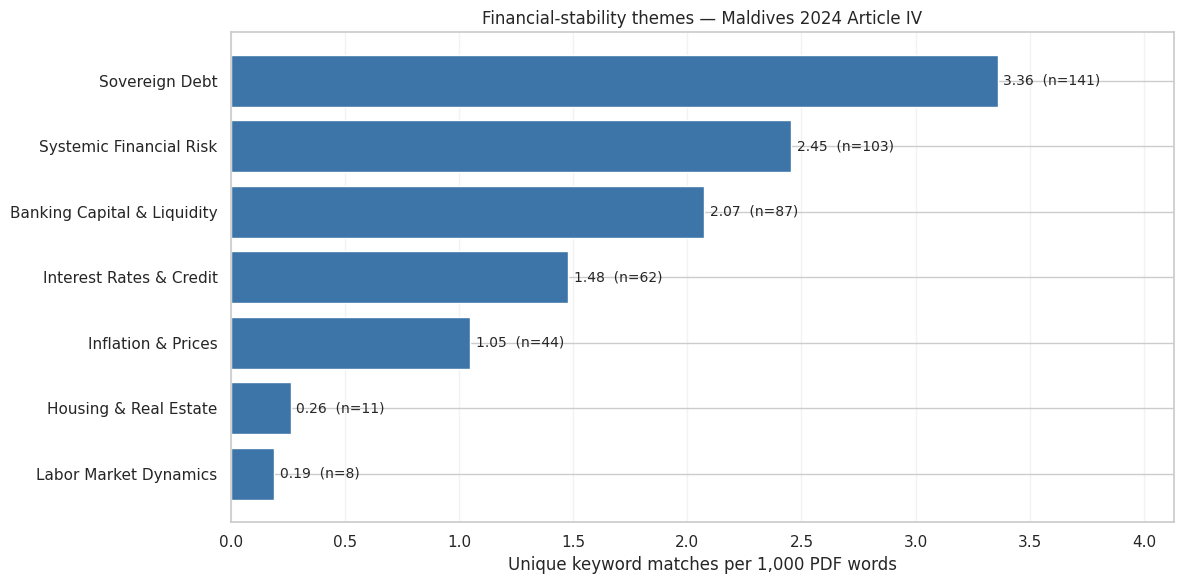

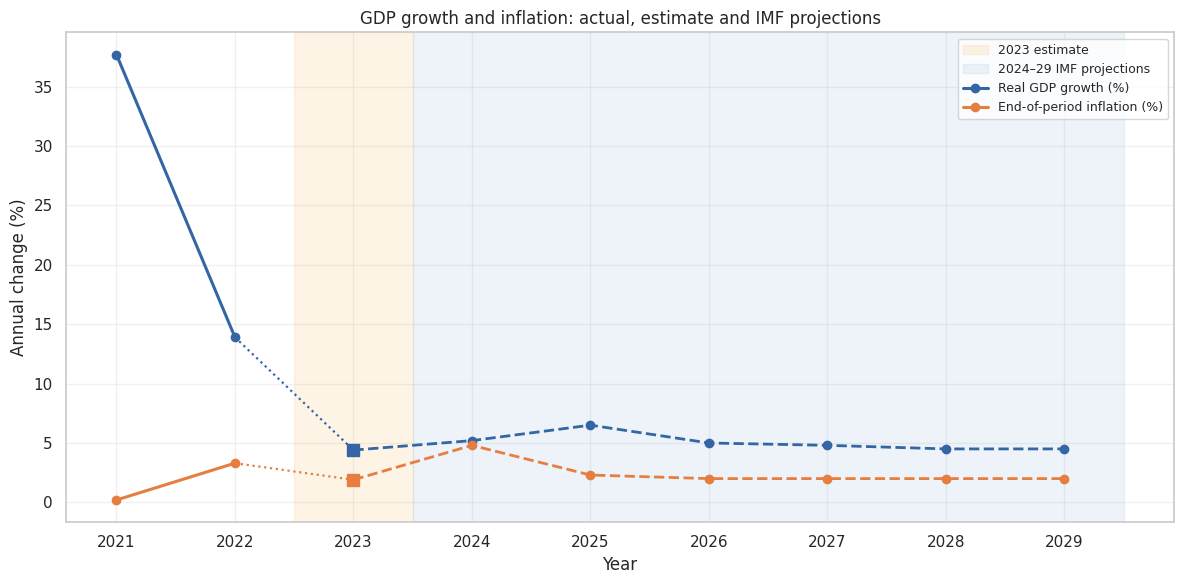

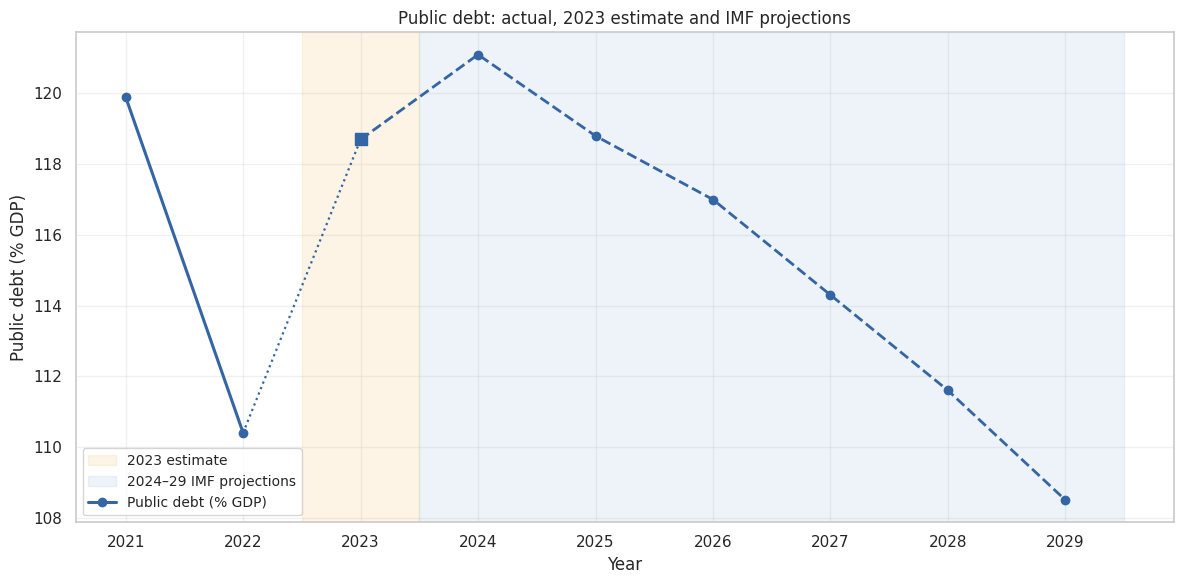

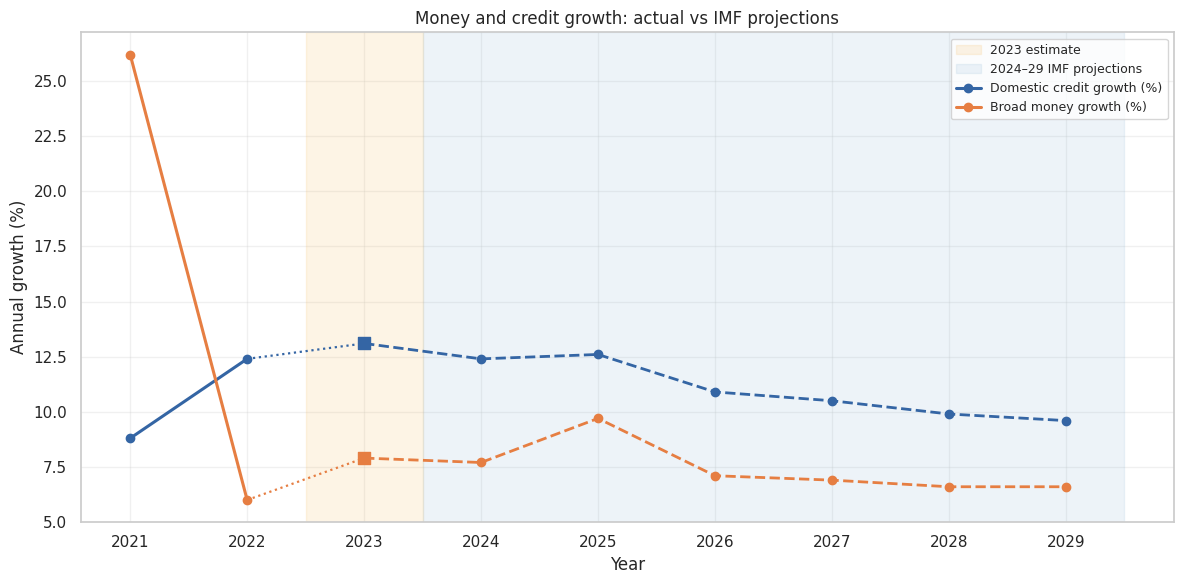

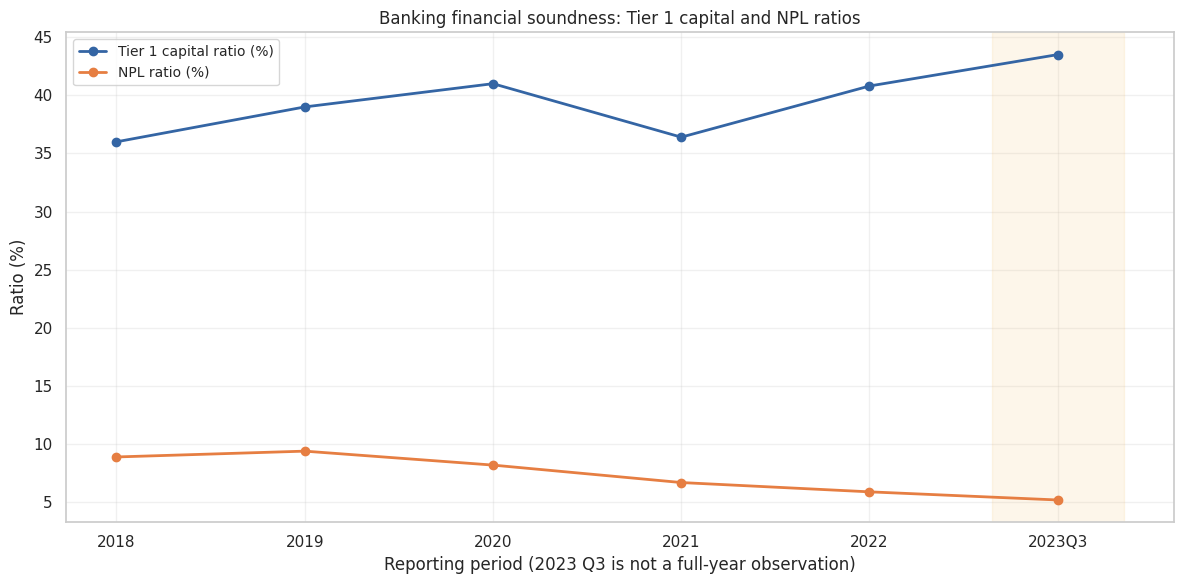

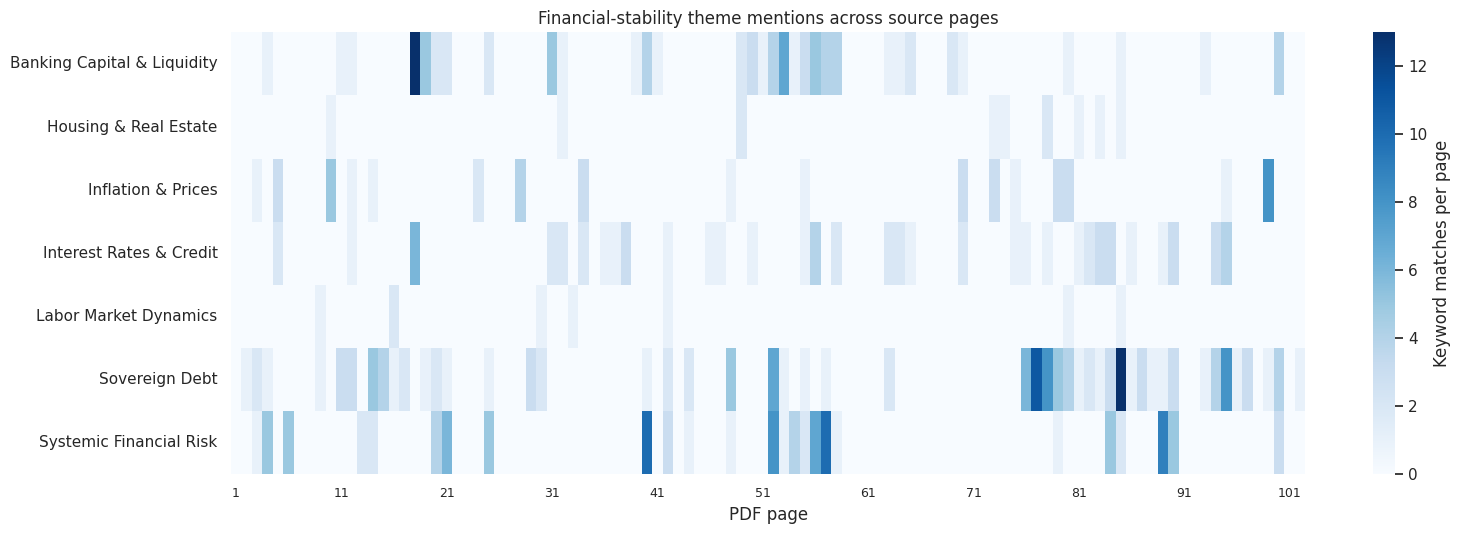

All six dashboard figures saved to: imf_2024_outputs/figures


In [ ]:
"""Generate high-resolution financial charts and theme visualisations."""

# 1. Theme frequency: normalized density and raw matches
# 2–4. Actual (2021–22), estimate (2023), projections (2024–29)
# Source classification is taken from the IMF table's column headings.
# 2023 is an estimate; it must not be labelled an actual observation.
# Actual observations: through 2022
# 2023 estimate: separate marker
# Connect actual to estimate, without presenting it as an actual year
# Projections: dashed, connected to the 2023 estimate
# 5. Financial soundness: 2023 Q3 is a quarter, not a full-year value
# 6. Page-by-page heatmap with legible sparse page ticks

sns.set_theme(style='whitegrid', context='notebook')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current Matplotlib figure as a high-resolution PNG.

    Args:
        name (str): Filename stem without the extension.

    Returns:
        None: Saves the figure under the configured figures directory.
    """
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=320, bbox_inches='tight')
    plt.show()
plot_data = theme_totals.sort_values('per_1000_words').copy()
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(plot_data['theme'], plot_data['per_1000_words'], color='#3e75a9')
ax.set(xlabel='Unique keyword matches per 1,000 PDF words', title='Financial-stability themes — Maldives 2024 Article IV')
ax.set_xlim(0, max(0.5, plot_data['per_1000_words'].max() * 1.23))
for bar, (_, record) in zip(bars, plot_data.iterrows()):
    ax.text(bar.get_width() + 0.025, bar.get_y() + bar.get_height() / 2, f"{record['per_1000_words']:.2f}  (n={int(record['mentions'])})", va='center', fontsize=10)
ax.grid(axis='x', alpha=0.25)
savefig('01_theme_density')

def plot_status_series(ax, data, col, color, label):
    """Plot historical, estimated, and projected financial values.

    Args:
        ax: Matplotlib axes on which to draw the series.
        data (pandas.DataFrame): Data containing year and indicator columns.
        col (str): Indicator column name.
        color (str): Matplotlib-compatible line colour.
        label (str): Series legend label.

    Returns:
        None: Modifies the supplied axes.
    """
    x = data['year'].to_numpy()
    y = data[col].to_numpy()
    actual = x <= 2022
    ax.plot(x[actual], y[actual], marker='o', linestyle='-', linewidth=2.2, color=color, label=label)
    est = x == 2023
    ax.scatter(x[est], y[est], color=color, marker='s', s=65, zorder=5)
    bridge = (x >= 2022) & (x <= 2023)
    ax.plot(x[bridge], y[bridge], linestyle=':', color=color, linewidth=1.6)
    future = x >= 2023
    ax.plot(x[future], y[future], linestyle='--', marker='o', linewidth=2, color=color)

def shade_status(ax):
    """Shade estimated and projected periods on a financial chart.

    Args:
        ax: Matplotlib axes to annotate.

    Returns:
        None: Adds forecast shading, year ticks, and a grid.
    """
    ax.axvspan(2022.5, 2023.5, color='#f6bd60', alpha=0.16, label='2023 estimate')
    ax.axvspan(2023.5, 2029.5, color='#78a9cf', alpha=0.13, label='2024–29 IMF projections')
    ax.set_xticks(YEARS)
    ax.grid(alpha=0.28)
fig, ax = plt.subplots(figsize=(12, 6))
shade_status(ax)
plot_status_series(ax, wide, 'Real GDP growth (%)', '#3465a4', 'Real GDP growth (%)')
plot_status_series(ax, wide, 'Inflation, end-of-period (%)', '#e67e42', 'End-of-period inflation (%)')
ax.set(xlabel='Year', ylabel='Annual change (%)', title='GDP growth and inflation: actual, estimate and IMF projections')
ax.legend(fontsize=9, loc='upper right')
savefig('02_gdp_inflation_trends')
fig, ax = plt.subplots(figsize=(12, 6))
shade_status(ax)
plot_status_series(ax, wide, 'Public debt (% GDP)', '#3465a4', 'Public debt (% GDP)')
ax.set(xlabel='Year', ylabel='Public debt (% GDP)', title='Public debt: actual, 2023 estimate and IMF projections')
ax.legend(fontsize=10)
savefig('03_public_debt')
fig, ax = plt.subplots(figsize=(12, 6))
shade_status(ax)
plot_status_series(ax, wide, 'Domestic credit growth (%)', '#3465a4', 'Domestic credit growth (%)')
plot_status_series(ax, wide, 'Broad money growth (%)', '#e67e42', 'Broad money growth (%)')
ax.set(xlabel='Year', ylabel='Annual growth (%)', title='Money and credit growth: actual vs IMF projections')
ax.legend(fontsize=9)
savefig('04_credit_money_growth')
fig, ax = plt.subplots(figsize=(12, 6))
for col, color in [('Tier 1 capital ratio (%)', '#3465a4'), ('NPL ratio (%)', '#e67e42')]:
    ax.plot(fsi['period'].astype(str), fsi[col], marker='o', linewidth=2, color=color, label=col)
ax.axvspan(4.65, 5.35, color='#f6bd60', alpha=0.13)
ax.set(xlabel='Reporting period (2023 Q3 is not a full-year observation)', ylabel='Ratio (%)', title='Banking financial soundness: Tier 1 capital and NPL ratios')
ax.legend(fontsize=10)
ax.grid(alpha=0.28)
savefig('05_banking_fsi')
heat = theme_page.pivot(index='theme', columns='page', values='mentions').fillna(0)
fig, ax = plt.subplots(figsize=(16, 5.5))
sns.heatmap(heat, cmap='Blues', ax=ax, cbar_kws={'label': 'Keyword matches per page'})
step = 10 if len(heat.columns) > 60 else 5
idx = np.arange(0, len(heat.columns), step)
ax.set_xticks(idx + 0.5)
ax.set_xticklabels([str(heat.columns[i]) for i in idx], rotation=0, fontsize=9)
ax.set(xlabel='PDF page', ylabel='', title='Financial-stability theme mentions across source pages')
savefig('06_theme_heatmap')
print('All six dashboard figures saved to:', FIG)


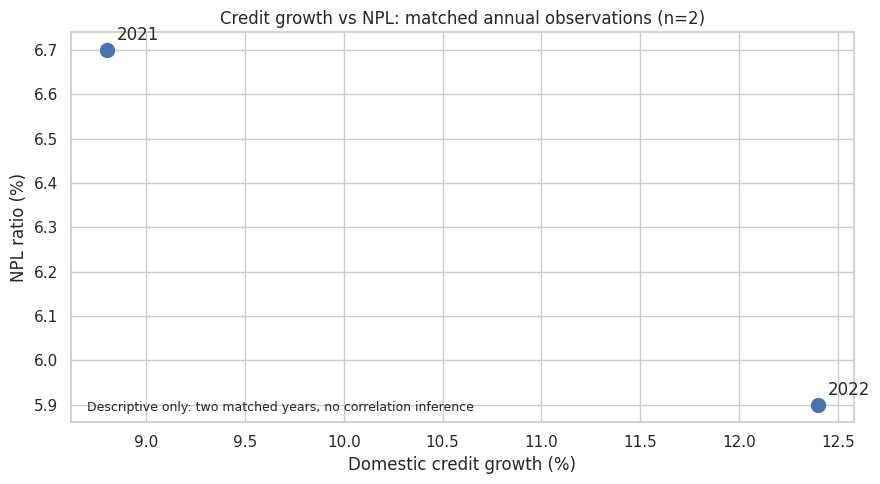

Saved plots: 7


In [ ]:
"""Create a supplementary credit-growth versus NPL comparison."""

# Supplementary scatter: credit growth vs NPL only for matched periods.
# Credit is annual; NPL is available annually 2018–22, then 2023Q3 (not comparable to full-year 2023).
# Plot judge scores only when validated JSON scores exist; do not invent accuracy percentages.

matched = pd.DataFrame({'year': [2021, 2022], 'credit_growth_pct': [8.8, 12.4], 'npl_ratio_pct': [6.7, 5.9]})
matched.to_json(OUT / 'credit_npl_matched.json', orient='records', indent=2)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(matched.credit_growth_pct, matched.npl_ratio_pct, s=100)
for r in matched.itertuples():
    ax.annotate(str(r.year), (r.credit_growth_pct, r.npl_ratio_pct), xytext=(7, 7), textcoords='offset points')
ax.set(xlabel='Domestic credit growth (%)', ylabel='NPL ratio (%)', title='Credit growth vs NPL: matched annual observations (n=2)')
ax.text(0.02, 0.03, 'Descriptive only: two matched years, no correlation inference', transform=ax.transAxes, fontsize=9)
savefig('07_credit_vs_npl')
print('Saved plots:', len(list(FIG.glob('*.png'))))


## Methodology and limitations

- The report table classifies 2021–22 as actual observations, 2023 as an estimate, and 2024–29 as projections; plots distinguish these using line styles and shading. Verify these labels against the source table.
- Theme counts are keyword frequencies, **not** measurements of economic risk severity. The bar chart shows normalized density and raw counts.
- The 2023 Q3 banking figures are quarterly observations, not annual figures.
- Missing JSON indicators remain `null` and must not be invented.
- Figures are saved at 320 DPI. Gemini-generated summaries and evaluator scores require a working API key.
